> **Trainierte Modelle:** Dieses Notebook lädt das fertige Modell aus `models/` und trainiert nicht neu. Zum Neutrainieren in den Parametern `TRAIN_MODEL = True` setzen.

## 💭 Ausgangspunkt: die Frage, die diese Version beantwortet

**Beobachtung nach v3:** Die Rekonstruktionen sind weiterhin deutlich unscharf. Die Klassifizierung hat sich nur mäßig verbessert.

**Status dieses Notebooks: neu aufgebaut, nicht vollständig trainiert.** Alle Zellen wurden mit einer sehr kleinen Testkonfiguration geprüft (1 Epoche, 200 Bilder). Das zeigt nur, dass der Code läuft. **Für Schärfe und Klassifizierung gibt es noch keine Ergebnisse**, hier ist also nicht belegt, dass v4 besser ist als v3.

**Warum das frühere v4 nicht mehr lief:** In der Umgebung `embeddings312` fehlten `scikit-learn` und `scipy`, sodass die Import-Zelle fehlschlug und nichts danach lief. Beide sind jetzt installiert. Warum `scikit-learn` nach dem v3-Lauf verschwunden ist, ist unbekannt.

---

## 📝 Changelog: v4 gegenüber v3

**Grundlage für den Neuaufbau** (einmalige Prüfung am gespeicherten v3-Modell, ohne Training):

| Repräsentation | Test-Pixel-MSE |
|---|---|
| Mittelwertbild vorhersagen | 0,0618 |
| PCA, 32 Dimensionen | 0,01247 |
| **v3-Autoencoder, 32 Dimensionen** | **0,01125** |
| PCA, 128 Dimensionen | 0,00513 |
| PCA, 256 Dimensionen | 0,00267 |
| PCA, 512 Dimensionen | 0,00107 |

Das frühere v4 änderte nur den Loss und blieb bei 32 Dimensionen, wodurch die größte gemessene Grenze bestehen blieb.

| # | Einstellung | v3 | v4 | Warum |
|---|---|---|---|---|
| 1 | `EMBEDDING_DIM` | 32 | **256** | Lässt feine Details durch den Engpass |
| 2 | Loss | `mse` | **`mse` + `PERCEPTUAL_WEIGHT` × VGG16-Feature-MSE** | Bestraft falsche Struktur, statt einen sicheren Mittelwert zu belohnen |
| 3 | `PERCEPTUAL_WEIGHT` | keiner | **`1e-6`** | Das alte `1e-5` machte den VGG-Term bei einem untrainierten Modell etwa 55-mal so groß wie den Pixel-Term. `1e-6` ergibt etwa das 5,6-Fache. Es ist ein ungetesteter Startwert |
| 4 | Trainingsbilder | 50.000 | **`TRAIN_SAMPLES = 10000`** | Jeder Schritt ist auf dieser CPU etwa 5-mal langsamer als in v3 (etwa 0,85 s gegenüber 0,17 s) |
| 5 | Validierungsbilder | 10.000 | **`VAL_SAMPLES = 2000`** | Gleicher Grund |
| 6 | `EPOCHS` | 25 | **15** | Gleicher Grund. Early Stopping und LR-Reduktion sind unverändert |
| 7 | Abschnitt 4a | keiner | **Schärfe und Pixel-MSE, v3 gegenüber v4** | `val_loss` ist zwischen den beiden Versionen nicht vergleichbar |
| 8 | Abschnitt 5b | Pixel gegenüber Embedding | **PCA-Basislinie gleicher Größe ergänzt** | Zeigt, ob der Autoencoder lineare Kompression schlägt |
| 9 | Artefakte | `_v3` | **`_v4`** | `models/*_v4.keras`, `checkpoint_v4.keras`, `logs_v4` |

Die Encoder- und Decoder-Layer sind bis auf die Embedding-Größe unverändert.

**Laufzeit:** etwa 25–30 Minuten auf diesem reinen CPU-Rechner, geschätzt aus etwa 0,85 s/Schritt im abgebrochenen vollständigen Lauf. Der Lauf beansprucht den Großteil der CPU. Für einen vollständigen Lauf auf einer GPU (z. B. Colab) setze `TRAIN_SAMPLES = None`, `VAL_SAMPLES = None` und `EPOCHS = 25`.

**Grenzen dieses Aufbaus:**
- Zwei Dinge ändern sich gleichzeitig (Embedding-Größe und Loss), sodass sich ein Unterschied zwischen v3 und v4 keinem davon allein zuschreiben lässt. Um sie zu trennen, einmal mit `PERCEPTUAL_WEIGHT = 0` laufen lassen.
- v4 trainiert auf einem Fünftel der Bilder von v3 und startet damit im Nachteil.
- Zu erwarten ist weniger Unschärfe, keine fotoscharfen Bilder. Ein Perceptual Loss ohne Adversarial-Term lässt meist eine gewisse Weichheit übrig.
- **Bei der Klassifizierung ist keine große Verbesserung zu erwarten.** Das Ziel sieht die Labels weiterhin nie, daher hilft ein größerer Engpass den Klassen-Proben möglicherweise nicht.


# Autoencoder auf CIFAR-10

## Aufgabenbeschreibung

Wir haben gesehen, wie man einen Autoencoder für die Graustufenbilder des Fashion-MNIST-Datensatzes baut. In dieser Übung baust du einen für den CIFAR-10-Datensatz (https://www.cs.toronto.edu/~kriz/cifar.html). Dieser Datensatz enthält **Farbbilder** mit einer Auflösung von 32x32.

### Vorbereitung


In [1]:
import matplotlib.pyplot as plt


def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
):
    """
    Zeigt n Bilder aus jedem der übergebenen Arrays an.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()


In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import keras
from tensorflow.keras import layers, models, datasets, callbacks
from tensorflow.keras.applications import vgg16
import tensorflow.keras.backend as K

# v3-Ergänzung: für die PCA-/t-SNE-Visualisierungen und die k-NN-Probe in den
# Abschnitten 5a/5b unten.
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# v4-Ergänzung: für die Schärfemetrik über die Laplace-Varianz in Abschnitt 4a
# unten.
from scipy.ndimage import convolve


I0000 00:00:1793541492.105991 1893347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793541494.038231 1893347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameter <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 256
EPOCHS = 15

# CPU-freundliche Teilmenge; auf einer GPU beide auf None setzen, um alle Bilder zu nutzen.
TRAIN_SAMPLES = 10000
VAL_SAMPLES = 2000

VGG_LAYER_NAMES = ["block1_conv2", "block2_conv2", "block3_conv3"]
PERCEPTUAL_WEIGHT = 1e-6  # ungetesteter Startwert -- siehe Changelog, Zeile 3


# Eigene Modelle laden statt neu trainieren. True trainiert neu.
TRAIN_MODEL = False

## 1. Daten vorbereiten <a name="prepare"></a>

In [4]:
# Daten laden
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

In [5]:
# Daten vorverarbeiten

def preprocess(imgs):
    """
    Normalisiert die Bilder und bringt sie in die richtige Form
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = imgs.reshape(len(imgs),imgs.shape[1],imgs.shape[2],3)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

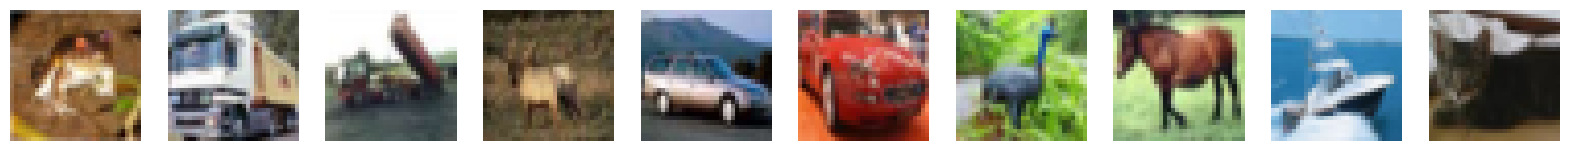

In [6]:
# Einige Bilder aus dem Trainingsset anzeigen
display(x_train)

## 2. Autoencoder aufbauen <a name="build"></a>

In [7]:
# Encoder
# (unverändert gegenüber v3: 4 Conv2D-Stufen, 32->64->128->256 Filter, mit
# BatchNormalization + Activation("relu") nach jeder Stufe.)
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input"
)

x = layers.Conv2D(32, (3, 3), strides=2, padding="same")(encoder_input)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(64, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(128, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(256, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

shape_before_flattening = K.int_shape(x)[1:]  # wird vom Decoder gebraucht!

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 256)            │       262,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 652,736 (2.49 MB)

 Trainable params: 651,776 (2.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
# Decoder
# (unverändert gegenüber v3: spiegelt die 4 Stufen des Encoders, gleiche BatchNormalization.)
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)

x = layers.Conv2DTranspose(256, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(128, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(64, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(32, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

decoder_output = layers.Conv2D(
    CHANNELS,
    (3, 3),
    strides=1,
    activation="sigmoid",
    padding="same",
    name="decoder_output",
)(x)

decoder = models.Model(decoder_input, decoder_output, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 4, 4, 256)      │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 8, 8, 128)      │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,243,331 (4.74 MB)

 Trainable params: 1,242,371 (4.74 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
# Autoencoder
autoencoder = models.Model(
    encoder_input, decoder(encoder_output), name="autoencoder"
)  # decoder(encoder_output)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 32, 32, 3)      │     1,243,331 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,896,067 (7.23 MB)

 Trainable params: 1,894,147 (7.23 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 2a. Perceptual Loss: ein eingefrorener VGG16-Merkmalsextraktor <a name="perceptual"></a>

Ein Perceptual Loss vergleicht Bilder im Merkmalsraum eines Netzes, das bereits auf natürlichen Bildern trainiert wurde, statt im rohen Pixelraum. Wir verwenden ein auf ImageNet vortrainiertes, eingefrorenes (nie aktualisiertes) `VGG16` und lesen die Aktivierungen einiger früher und mittlerer Faltungsschichten aus.

CIFAR-10-Bilder haben nur 32×32 Pixel, und VGG16 halbiert die räumliche Größe in jeder Pooling-Stufe. So schrumpft eine 32×32-Eingabe im Netz:

| Layer | räumliche Größe |
|---|---|
| `block1_conv1` / `block1_conv2` | 32×32 |
| `block1_pool` | 16×16 |
| `block2_conv1` / `block2_conv2` | 16×16 |
| `block2_pool` | 8×8 |
| `block3_conv1` / `block3_conv2` / `block3_conv3` | 8×8 |
| `block3_pool` | 4×4 |
| `block4_*` | 4×4 |
| `block5_*` | 2×2, nach dem letzten Pooling 1×1 |

Wir verwenden `block1_conv2`, `block2_conv2` und `block3_conv3` (32×32, 16×16, 8×8): Kanten- und Texturmerkmale niedriger und mittlerer Ebene, die für ein 32×32-Bild noch räumlich aussagekräftig sind. `block4_*`/`block5_*` sind bewusst ausgeschlossen: Bei 4×4 oder 1–2×2 kodieren sie vor allem „durchschnittliche Farbe und Helligkeit des ganzen Bildes“, was der Pixel-MSE bereits erfasst, und kosten dabei etwa den doppelten Rechenaufwand bei wenig zusätzlichem Signal.

In [10]:
vgg = vgg16.VGG16(
    weights="imagenet", include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
)
vgg.trainable = False

feature_extractor = models.Model(
    vgg.input,
    [vgg.get_layer(name).output for name in VGG_LAYER_NAMES],
    name="vgg16_feature_extractor",
)
feature_extractor.trainable = False

print(feature_extractor.output_shape)

[(None, 32, 32, 64), (None, 16, 16, 128), (None, 8, 8, 256)]


In [11]:
def to_vgg_input(images_01):
    """Wandelt Bilder vom [0, 1]-RGB-Bereich dieses Notebooks in das Format um, das die
    ImageNet-Gewichte von VGG16 erwarten (Skala 0-255, BGR-Reihenfolge, ImageNet-Mittelwert
    abgezogen)."""
    return vgg16.preprocess_input(images_01 * 255.0)

In [12]:
# v4: die rohen Größenordnungen des Pixel- und des Feature-Loss-Terms am frisch
# initialisierten (untrainierten) Autoencoder prüfen, *bevor* PERCEPTUAL_WEIGHT
# gewählt wird -- siehe Changelog, Zeile 3. Bei naiver Gleichgewichtung würde der
# numerisch größere Term den Gradienten dominieren.
diagnostic_batch = x_train[:BATCH_SIZE]
diagnostic_recon = autoencoder(diagnostic_batch, training=False).numpy()

pixel_mse_sample = np.mean((diagnostic_batch - diagnostic_recon) ** 2)

true_feats_sample = feature_extractor(to_vgg_input(diagnostic_batch), training=False)
pred_feats_sample = feature_extractor(to_vgg_input(diagnostic_recon), training=False)
per_layer_mse = [
    float(np.mean((t.numpy() - p.numpy()) ** 2))
    for t, p in zip(true_feats_sample, pred_feats_sample)
]
feature_mse_sample = float(np.mean(per_layer_mse))

print(f"pixel MSE (unweighted):           {pixel_mse_sample:.6f}")
print(f"per-layer feature MSE:            {[round(v, 2) for v in per_layer_mse]}")
print(f"feature MSE (unweighted, avg):    {feature_mse_sample:.6f}")
print(f"ratio pixel_mse / feature_mse:    {pixel_mse_sample / feature_mse_sample:.8f}")
print(f"PERCEPTUAL_WEIGHT * feature_mse:  {PERCEPTUAL_WEIGHT * feature_mse_sample:.6f}")

pixel MSE (unweighted):           0.060592
per-layer feature MSE:            [53228.78, 366828.97, 588282.5]
feature MSE (unweighted, avg):    336113.416667
ratio pixel_mse / feature_mse:    0.00000018
PERCEPTUAL_WEIGHT * feature_mse:  0.336113


In [13]:
@keras.saving.register_keras_serializable(package="autoencoder_v4")
def perceptual_loss(y_true, y_pred):
    pixel_mse = K.mean(K.square(y_true - y_pred), axis=[1, 2, 3])

    true_feats = feature_extractor(to_vgg_input(y_true), training=False)
    pred_feats = feature_extractor(to_vgg_input(y_pred), training=False)
    feature_mse = sum(
        K.mean(K.square(t - p), axis=[1, 2, 3]) for t, p in zip(true_feats, pred_feats)
    ) / len(true_feats)

    return pixel_mse + PERCEPTUAL_WEIGHT * feature_mse

## 3. Autoencoder trainieren <a name="train"></a>

In [14]:
# Autoencoder kompilieren
# v4: Loss "mse" -> perceptual_loss (Pixel-MSE + gewichteter VGG-Feature-MSE) --
# siehe Changelog, Zeile 2, und die Diagnosezelle in Abschnitt 2a.
autoencoder.compile(optimizer="adam", loss=perceptual_loss)

In [15]:
# Checkpoint zum Speichern des Modells anlegen
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint_v4.keras",
    save_weights_only=False,
    save_freq="epoch",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs_v4")
early_stopping_callback = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr_callback = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1
)


In [16]:
if TRAIN_MODEL:
    # Geschätzt 25-30 Minuten auf der CPU mit der Standard-Teilmenge -- siehe Changelog.
    x_fit = x_train[:TRAIN_SAMPLES]
    x_val = x_test[:VAL_SAMPLES]

    autoencoder.fit(
        x_fit,
        x_fit,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        validation_data=(x_val, x_val),
        callbacks=[
            model_checkpoint_callback,
            tensorboard_callback,
            early_stopping_callback,
            reduce_lr_callback,
        ],
    )
else:
    autoencoder.set_weights(models.load_model("./models/autoencoder_v4.keras", compile=False).get_weights())

In [17]:
if TRAIN_MODEL:
    # Finale Modelle speichern
    # v4: mit _v4-Suffix gespeichert -- siehe Changelog, Zeile 9.
    from pathlib import Path
    Path("./models").mkdir(parents=True, exist_ok=True)
    autoencoder.save("./models/autoencoder_v4.keras")
    encoder.save("./models/encoder_v4.keras")
    decoder.save("./models/decoder_v4.keras")

## 4. Rekonstruieren mit dem Autoencoder <a name="reconstruct"></a>

In [18]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

  1/157 ━━━━━━━━━━━━━━━━━━━━ 53s 345ms/step

  4/157 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step  

  8/157 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step

 11/157 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step

 14/157 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step

 17/157 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step

... (36 outputs left out)

155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step


Example real images


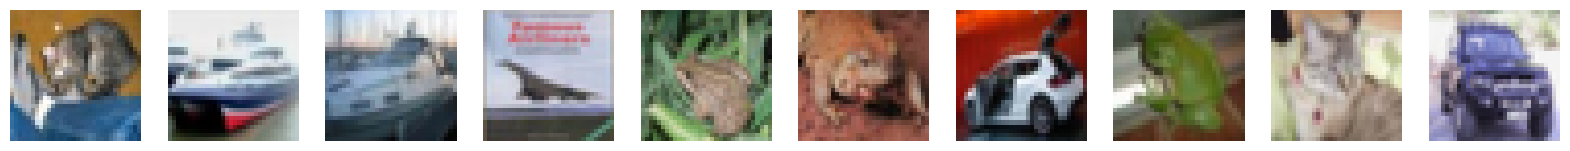

Reconstructions


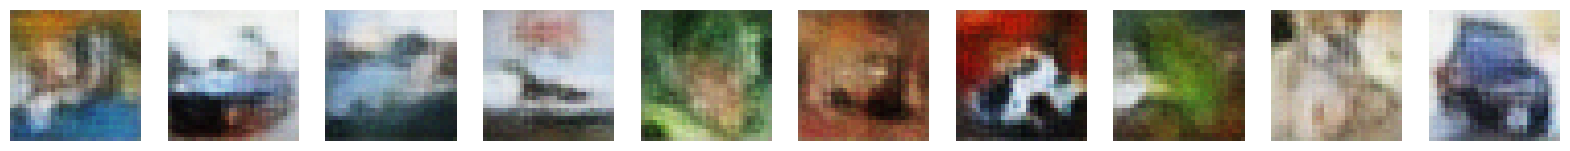

In [19]:
predictions = autoencoder.predict(example_images)

print("Example real images")
display(example_images)
print("Reconstructions")
display(predictions)

### 4a. Die Unschärfe quantifizieren: Schärfe über die Varianz des Laplace-Operators

Ein schneller Weg mit wenigen Abhängigkeiten, um zu messen, „wie unscharf“ ein Bild ist: den Luma-Kanal (Graustufen) mit einem 3×3-Laplace-Kernel (einem einfachen Kantendetektor) falten und die *Varianz* der Antwort betrachten. Scharfe Kanten und feine Textur erzeugen große, vielfältige Laplace-Antworten. Bei einem unscharfen Bild sind die Kanten weich, sodass die Antwort fast überall klein und flach bleibt, also eine geringere Varianz hat. Dieselbe Art von Metrik nutzen klassische Detektoren für unscharfe Fotos.

Wir vergleichen drei Gruppen auf denselben 5000 Beispielbildern: die Originalbilder (die Obergrenze), die Rekonstruktionen von v3 (neu geladen aus `models/autoencoder_v3.keras`, gespeichert vom bereits ausgeführten v3-Notebook) und die eigenen Rekonstruktionen dieses Notebooks (v4).

  1/157 ━━━━━━━━━━━━━━━━━━━━ 48s 311ms/step

  5/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step  

  9/157 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

 13/157 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

 17/157 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

 20/157 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step

... (34 outputs left out)

156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step


pixel MSE, v3 reconstructions: 0.01137
pixel MSE, v4 reconstructions: 0.00916
mean sharpness, ground truth:           0.03441
mean sharpness, v3 (plain mse) recon:    0.00211
mean sharpness, v4 (perceptual) recon:   0.02054


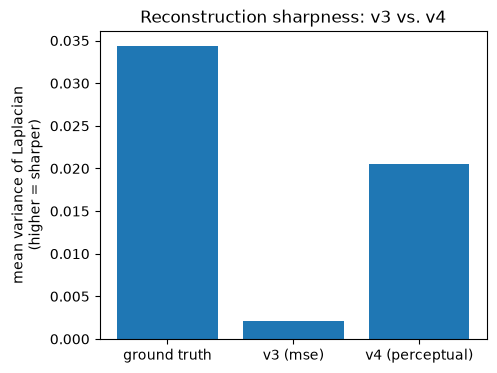

In [20]:
LAPLACIAN_KERNEL = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
LUMA_WEIGHTS = np.array([0.299, 0.587, 0.114], dtype=np.float32)  # Standardumrechnung RGB -> Luma


def sharpness_scores(images):
    """Varianz der Laplace-Antwort pro Bild; höher = schärfer."""
    return np.array([
        convolve(img @ LUMA_WEIGHTS, LAPLACIAN_KERNEL, mode="reflect").var()
        for img in images
    ])


autoencoder_v3 = models.load_model("./models/autoencoder_v3.keras")
predictions_v3 = autoencoder_v3.predict(example_images)

sharpness_real = sharpness_scores(example_images)
sharpness_v3 = sharpness_scores(predictions_v3)
sharpness_v4 = sharpness_scores(predictions)

print(f"pixel MSE, v3 reconstructions: {np.mean((example_images - predictions_v3) ** 2):.5f}")
print(f"pixel MSE, v4 reconstructions: {np.mean((example_images - predictions) ** 2):.5f}")

print(f"mean sharpness, ground truth:           {sharpness_real.mean():.5f}")
print(f"mean sharpness, v3 (plain mse) recon:    {sharpness_v3.mean():.5f}")
print(f"mean sharpness, v4 (perceptual) recon:   {sharpness_v4.mean():.5f}")

plt.figure(figsize=(5, 4))
plt.bar(
    ["ground truth", "v3 (mse)", "v4 (perceptual)"],
    [sharpness_real.mean(), sharpness_v3.mean(), sharpness_v4.mean()],
)
plt.ylabel("mean variance of Laplacian\n(higher = sharper)")
plt.title("Reconstruction sharpness: v3 vs. v4")
plt.show()

## 5. Einbetten mit dem Encoder <a name="encode"></a>

In [21]:
# Beispielbilder kodieren
embeddings = encoder.predict(example_images)

  1/157 ━━━━━━━━━━━━━━━━━━━━ 27s 173ms/step

 12/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step   

 22/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 31/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 42/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 53/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

... (7 outputs left out)

143/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [22]:
# Einige Beispiele der Embeddings (die ersten 5 von EMBEDDING_DIM Werten)
print(embeddings[:10, :5])


[[ 0.21824212  0.96650124  4.9129963   1.2337397   0.10425419]
 [ 1.2561418   2.1020763  -2.8610005  -1.3156962  -0.564548  ]
 [ 1.5178099  -0.30796474  0.1597382  -0.6556013   0.04035574]
 [-0.72937834  1.4129922   2.7036624  -1.2424858  -1.3959967 ]
 [-0.57663935  1.7084087   0.10691797  1.7376397  -2.4437964 ]
 [-0.28926724  0.25116464 -0.0922344   0.7768786   1.4091786 ]
 [-1.6838665   1.4608124   2.1086392   2.1933894   3.2741873 ]
 [-0.01521443  1.3382995  -1.0642629   0.5477629  -0.7896331 ]
 [ 0.72893304 -1.2739377   1.8213514  -1.9956559  -1.8008376 ]
 [ 1.7323138   0.4154837  -1.4039767   2.7457228   0.61168283]]


### 5a. Einen höherdimensionalen latenten Raum visualisieren

Mit `EMBEDDING_DIM = 256` lässt sich das rohe Embedding nicht mehr direkt als Streudiagramm darstellen; zwei beliebige von 256 Achsen zu plotten, wäre genauso wenig aussagekräftig wie zuvor. Stattdessen projizieren wir das gesamte Embedding **nur zur Visualisierung** auf 2D, mit zwei Standardverfahren:

- **PCA**: eine schnelle, lineare Projektion auf die 2 Richtungen mit der größten Varianz. Gut als Plausibilitätsprüfung, kann aber nichtlineare Clusterstrukturen verbergen.
- **t-SNE**: eine nichtlineare Projektion, die gezielt lokale Nachbarschaften zu erhalten versucht. Sie zeigt tatsächlich vorhandene Clusterstrukturen im Embedding deshalb viel besser, ist aber langsamer und erhält globale Abstände nicht.

Überlappen sich die Klassen selbst in der t-SNE-Projektion stark, ist das ein deutliches Zeichen, dass das Embedding selbst die Klassen schlecht trennt (und nicht nur ein Artefakt des 2D-Plots).

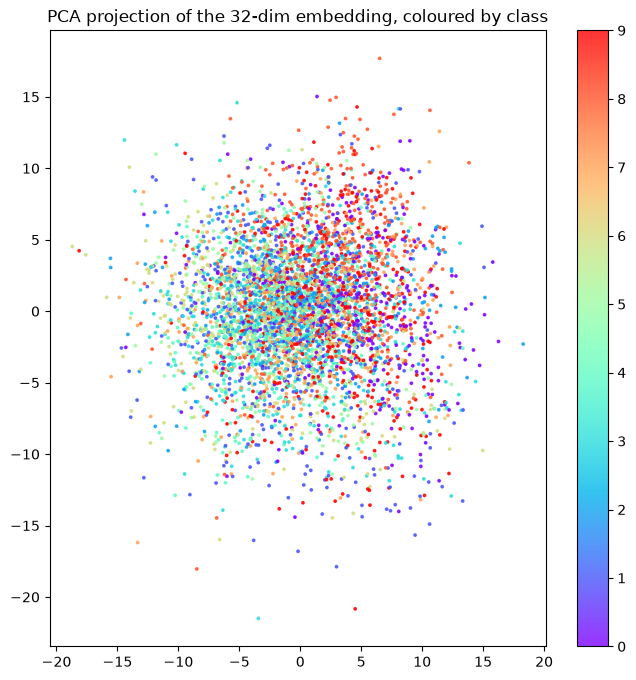

In [23]:
# PCA-Projektion des Embeddings, nach Klasse eingefärbt
pca = PCA(n_components=2)
embeddings_pca = pca.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_pca[:, 0],
    embeddings_pca[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title("PCA projection of the 32-dim embedding, coloured by class")
plt.show()

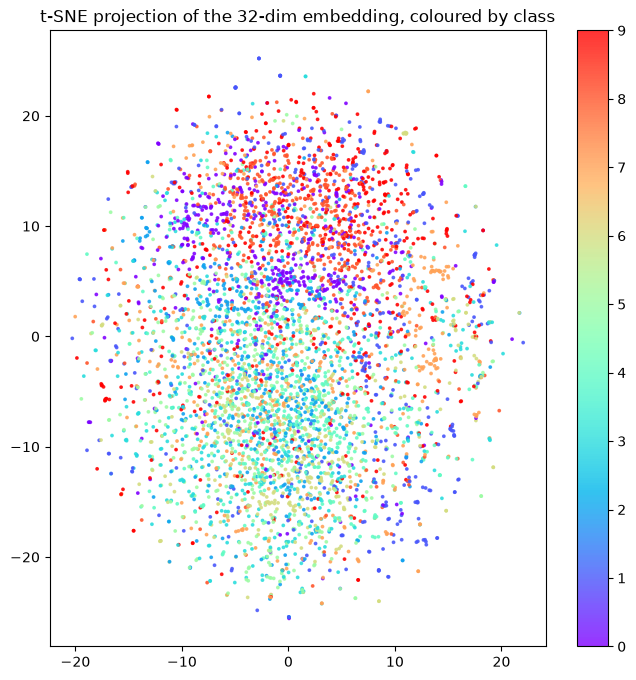

In [24]:
# t-SNE-Projektion des Embeddings, nach Klasse eingefärbt
tsne = TSNE(n_components=2, init="pca", perplexity=30, random_state=42)
embeddings_tsne = tsne.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title("t-SNE projection of the 32-dim embedding, coloured by class")
plt.show()

### 5b. Klassentrennung quantifizieren: eine k-NN-Probe

Statt die Trennung nach Augenmaß zu beurteilen, ist es aussagekräftiger, das Embedding als Merkmale für einen einfachen Klassifikator zu verwenden und die Genauigkeit auf zurückgehaltenen Daten zu messen. Trägt das Embedding tatsächlich Klasseninformation, sollte selbst ein einfacher k-NN-Klassifikator das Raten (10 % bei 10 ausgeglichenen Klassen) deutlich schlagen. Schlägt er es kaum, ist das Embedding nicht klassentrennend, wie auch immer es im 2D-Plot aussieht, und kein Plot ändert daran etwas. Ist Klassentrennung tatsächlich das Ziel, muss sich das Trainingsziel selbst ändern (z. B. durch einen überwachten oder kontrastiven Loss).

Wir vergleichen drei Merkmalssätze auf demselben Train/Test-Split der 5000 Beispielbilder: rohe, flach gemachte Pixel, eine PCA in der Größe des Embeddings und das Embedding des Autoencoders. Die Probe trainiert nur auf 4000 Bildern, ihre Zahlen unterschätzen also, was die Merkmale auf dem vollen Trainingsset erreichen könnten.

In [25]:
labels_flat = example_labels.ravel()
pixels_flat = example_images.reshape(len(example_images), -1)

(
    emb_train, emb_test,
    pix_train, pix_test,
    y_train_knn, y_test_knn,
) = train_test_split(
    embeddings,
    pixels_flat,
    labels_flat,
    test_size=0.2,
    random_state=42,
    stratify=labels_flat,
)

pca_probe = PCA(n_components=EMBEDDING_DIM, random_state=42).fit(pix_train)
feature_sets = {
    "raw pixels": (pix_train, pix_test),
    f"{EMBEDDING_DIM}-dim PCA": (pca_probe.transform(pix_train), pca_probe.transform(pix_test)),
    f"{EMBEDDING_DIM}-dim AE embedding": (emb_train, emb_test),
}

for name, (features_train, features_test) in feature_sets.items():
    knn = KNeighborsClassifier(n_neighbors=5).fit(features_train, y_train_knn)
    accuracy = accuracy_score(y_test_knn, knn.predict(features_test))
    print(f"k-NN accuracy on {name}: {accuracy:.3f}")
print("random-guess baseline (10 classes): 0.100")


k-NN accuracy on raw pixels: 0.269
k-NN accuracy on 256-dim PCA: 0.279
k-NN accuracy on 256-dim AE embedding: 0.266
random-guess baseline (10 classes): 0.100


### Fazit: wie die Ergebnisse zu lesen sind

Aus dem Lauf oben ergänzen; dieses Notebook hat noch keine Ergebnisse aus einem vollständigen Training.

- **Unschärfe:** Abschnitt 4a (Schärfe und Pixel-MSE) und die Bildraster mit v3 vergleichen. Um zu sehen, wie viel allein vom größeren Engpass kommt, mit `PERCEPTUAL_WEIGHT = 0` wiederholen.
- **Klassifizierung:** das Embedding mit der PCA-Zeile in Abschnitt 5b vergleichen. Schlägt es PCA nicht deutlich, hat der Autoencoder kaum Klasseninformation hinzugefügt.

**Einem einfachen Autoencoder wird nie gesagt, was eine Klasse ist.** Ist Klassentrennung das Ziel, sind die nächsten Schritte, nach steigendem Aufwand und Nutzen innerhalb dieser Arbeitsrichtung:

1. **Überwachter Autoencoder:** einen Klassifikationskopf auf das Embedding setzen, mit einem zusätzlichen Kreuzentropie-Loss auf `y_train`.
2. **Kontrastives bzw. selbstüberwachtes Lernen** (z. B. SimCLR): augmentierte Ansichten desselben Bildes zusammenziehen, ohne dass eine Rekonstruktion nötig ist.
3. **Ein überwachter CNN-Klassifikator:** Ist Genauigkeit das eigentliche Endziel, direkt darauf trainieren und den Engpass weglassen.

Ein VAE (`autoencoder_on_CIFAR-10_v2_vae.ipynb`) macht den latenten Raum glatter für das Generieren von Bildern. Das ist eine andere Eigenschaft als Klassentrennung.